# Extreme Value Modeling for Rare Event Analysis

### HIDSI Workshop — Waimea Bay Case Study

This notebook demonstrates two approaches to estimating the magnitude and probability of rare events using historical significant wave height observations.

**Methods:**
- Annual Maximum Method (AMM) using the Generalized Extreme Value (GEV) distribution
- Peaks Over Threshold (POT) using the Generalized Pareto Distribution (GPD)

**Dataset:** CDIP Station 106 — Waimea Bay, Oʻahu, Hawaiʻi

**Analysis period:** 2002–2025

**Workshop objectives:**
1. Identify extreme events from a time-series dataset.
2. Fit statistical distributions to selected extremes.
3. Estimate return levels for different return periods.
4. Compare results and assess model limitations.

**Data source:** [Coastal Data Information Program (CDIP)](https://cdip.ucsd.edu/)

Dataset was extracted from CDIP Station 106's historical NetCDF archive and prepared before the workshop. 

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import genextreme, genpareto

# Plot settings
WAVE_COLOR = '#A9A9A9'
AMM_COLOR = '#DC143C'
POT_COLOR = '#164E9D'
REF_COLOR = '#444444'

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.frameon': True
})

## 1. Dataset Preparation

We use historical wave observations from CDIP Station 106, located offshore of Waimea Bay on Oʻahu.

The dataset contains:

- **Hs:** Significant wave height (m)
- **Tp:** Peak wave period (s)
- **Ta:** Average wave period (s)
- **Time:** Observation timestamp (UTC)

The observations have been downloaded and prepared in advance. We load the dataset directly from GitHub to avoid requiring participants to access the original THREDDS server.

We convert the timestamps into Python datetime values and restrict the analysis to 2002–2025, excluding partial calendar years at the beginning and end of the record.

**Note:** Some years contain missing observations even though they fall within the selected calendar-year range.

In [2]:
# Load CDIP Station 106 wave data directly from GitHub
url = "https://raw.githubusercontent.com/lydia-rice/extreme-value-modeling-workshop/main/wave_data.zip"
df = pd.read_csv(url, compression="zip")

# Convert timestamps to datetime
df['Time'] = pd.to_datetime(df['Time'], format='%d-%b-%Y %H:%M:%S', utc=True)

# Exclude partial calendar years at the beginning and end of the record
# Retain observations from 2002–2025
df = df[(df['Time'].dt.year >= 2002) &
        (df['Time'].dt.year <= 2025)].copy()

# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 385112 entries, 767 to 385878
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype              
---  ------  --------------   -----              
 0   Time    385112 non-null  datetime64[us, UTC]
 1   Hs      385112 non-null  float64            
 2   Tp      385112 non-null  float64            
 3   Ta      385112 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(3)
memory usage: 11.8 MB


## 2. Exploring the Time Series

Before applying extreme value models, we examine the observations to understand their variability and identify potential limitations.

**Things to look for:**
- Seasonal patterns in wave height
- Large, infrequent wave events
- Gaps in the observational record
- Changes in variability over time

**Discussion:** Why might the largest wave heights occur during particular seasons, and how could missing observations influence estimates of extremes?

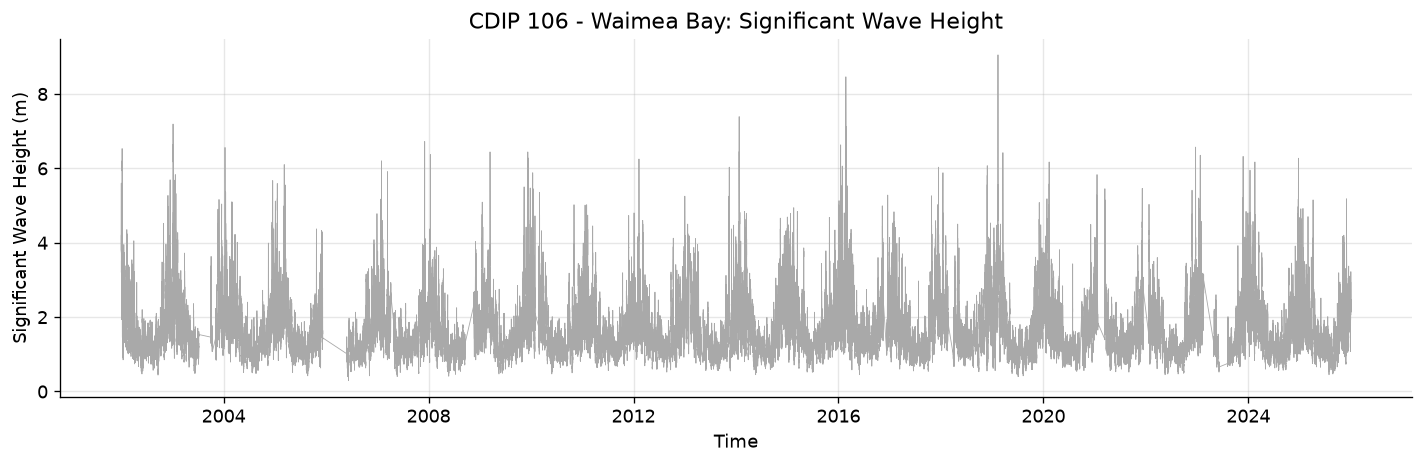

In [3]:
# Plot significant wave height time series
plt.figure(figsize=(12, 4))

plt.plot(df['Time'], df['Hs'], color=WAVE_COLOR, linewidth=0.5)

plt.xlabel('Time')
plt.ylabel('Significant Wave Height (m)')
plt.title('CDIP 106 - Waimea Bay: Significant Wave Height')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Annual Maximum Method (AMM)

The Annual Maximum Method selects the largest observation from each calendar year.

For a time series containing multiple years, this produces one maximum per year.

We use these annual maxima to fit a Generalized Extreme Value (GEV) distribution.

**Advantages:** Simple event selection and a consistent annual time scale.

**Limitations:** Other large events within the same year are discarded, and incomplete years may not capture the true annual maximum.

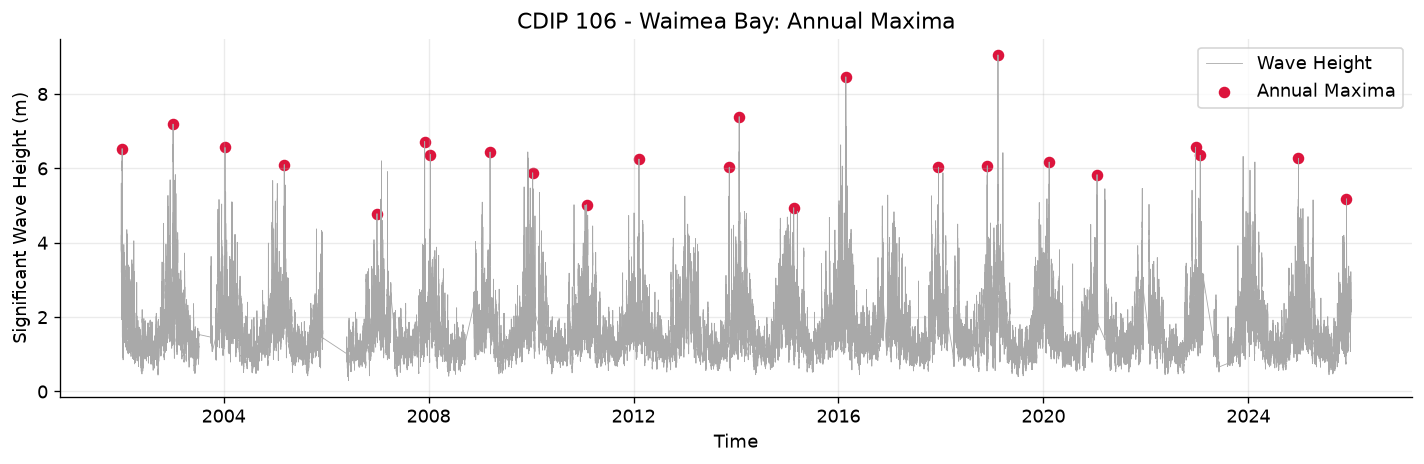

In [4]:
# Extract annual maxima
annual_max_rows = df.loc[df.groupby(df['Time'].dt.year)['Hs'].idxmax()]
Hs_max = annual_max_rows['Hs'].values

# Plot annual maxima
plt.figure(figsize=(12, 4))

plt.plot(df['Time'], df['Hs'],
         color=WAVE_COLOR, linewidth=0.5, label='Wave Height')

plt.scatter(annual_max_rows['Time'], annual_max_rows['Hs'],
            color=AMM_COLOR, s=35, label='Annual Maxima')

plt.xlabel('Time')
plt.ylabel('Significant Wave Height (m)')
plt.title('CDIP 106 - Waimea Bay: Annual Maxima')
plt.legend()
plt.tight_layout()
plt.show()

### Fitting the GEV Distribution

The GEV distribution is characterized by three parameters:

- **A — Location:** Controls the position of the distribution.
- **B — Scale:** Controls its spread.
- **C — Shape:** Controls the behavior of the upper tail.

We estimate these parameters from the observed annual maxima using SciPy's `genextreme.fit()` function.

**Important:** SciPy uses the opposite sign convention for the GEV shape parameter compared with the notation used in the workshop lecture. A negative shape parameter in our lecture's convention corresponds to a bounded upper tail.

In [5]:
# Fit GEV distribution
shape, loc, scale = genextreme.fit(Hs_max)

# Convert SciPy shape parameter to standard EVT convention
C = -shape
A = loc
B = scale

# Display fitted parameters
print(f"Location (A): {A:.3f} m")
print(f"Scale (B): {B:.3f} m")
print(f"Shape (C): {C:.3f}")

Location (A): 5.928 m
Scale (B): 0.808 m
Shape (C): -0.065


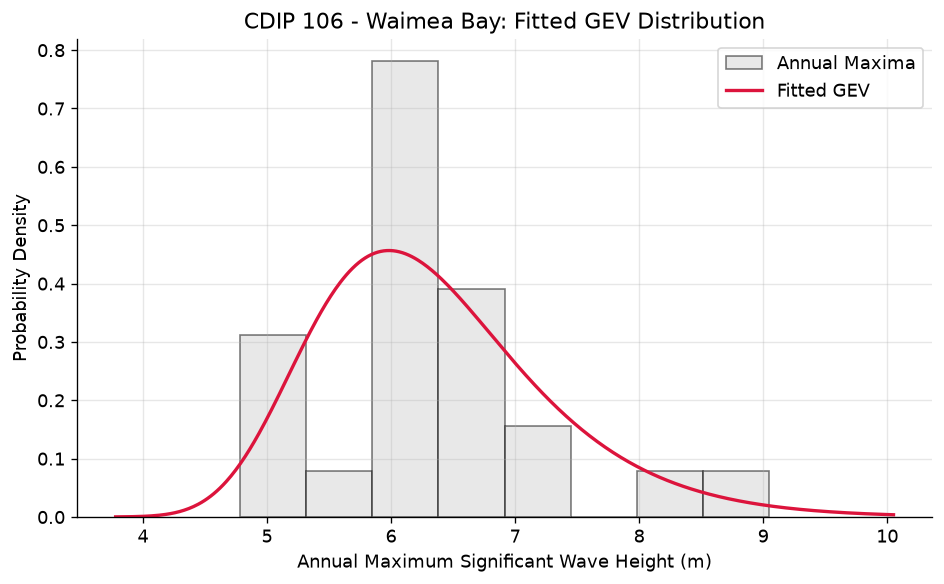

In [6]:
# Generate wave heights for fitted GEV curve
x = np.linspace(Hs_max.min() - 1, Hs_max.max() + 1, 500)

# Calculate fitted GEV probability density
pdf = genextreme.pdf(x, shape, loc=A, scale=B)

# Plot observed annual maxima and fitted GEV
plt.figure(figsize=(8, 5))

plt.hist(Hs_max, bins=8, density=True, alpha=0.5,
         color='lightgray', edgecolor='black', label='Annual Maxima')

plt.plot(x, pdf, color=AMM_COLOR, linewidth=2,
         label='Fitted GEV')

plt.xlabel('Annual Maximum Significant Wave Height (m)')
plt.ylabel('Probability Density')
plt.title('CDIP 106 - Waimea Bay: Fitted GEV Distribution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Estimating GEV Return Levels

A return level is the event magnitude associated with a specified return period.

For annual maxima, the return period is related to the annual exceedance probability by:

$$T_R = \frac{1}{1-F(h)}$$

We use the inverse of the fitted GEV cumulative distribution to estimate significant wave heights associated with 10-, 25-, 50-, and 100-year return periods.

SciPy's ppf() function is the inverse cumulative distribution function (CDF), which calculates the event magnitude associated with a specified non-exceedance probability.

In [7]:
# Return periods (years)
T = np.array([10, 25, 50, 100])

# Annual non-exceedance probabilities
P = 1 - 1/T

# Calculate GEV return levels
return_levels = genextreme.ppf(P, shape, loc=A, scale=B)

# Display results
gev_results = pd.DataFrame({
    'Return Period (years)': T,
    'Return Level (m)': return_levels
})

print(gev_results.round(2))

   Return Period (years)  Return Level (m)
0                     10              7.62
1                     25              8.26
2                     50              8.71
3                    100              9.14


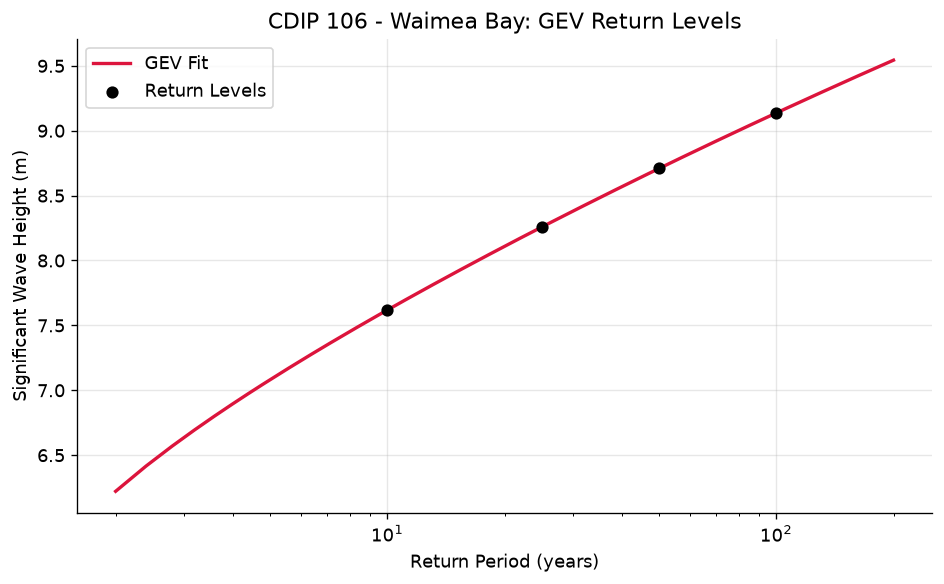

In [8]:
# Return periods from 2 to 200 years
T_plot = np.linspace(2, 200, 500)

# Calculate return levels
P_plot = 1 - 1/T_plot
Hs_return = genextreme.ppf(P_plot, shape, loc=A, scale=B)

# Plot return-level curve
plt.figure(figsize=(8, 5))

plt.plot(T_plot, Hs_return, color=AMM_COLOR,
         linewidth=2, label='GEV Fit')

# Mark calculated return levels
plt.scatter(T, return_levels, color='black',
            s=40, zorder=3, label='Return Levels')

plt.xscale('log')

plt.xlabel('Return Period (years)')
plt.ylabel('Significant Wave Height (m)')
plt.title('CDIP 106 - Waimea Bay: GEV Return Levels')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Peaks Over Threshold (POT)

Unlike AMM, which selects one maximum per year, the POT method considers events exceeding a specified threshold.

We first compare several candidate thresholds corresponding to the 95th, 97th, 98th, and 99th percentiles.

**Threshold selection involves a tradeoff:**
- Lower thresholds retain more observations but may include events that do not adequately follow the GPD tail approximation.
- Higher thresholds focus on larger events but retain fewer observations for fitting.

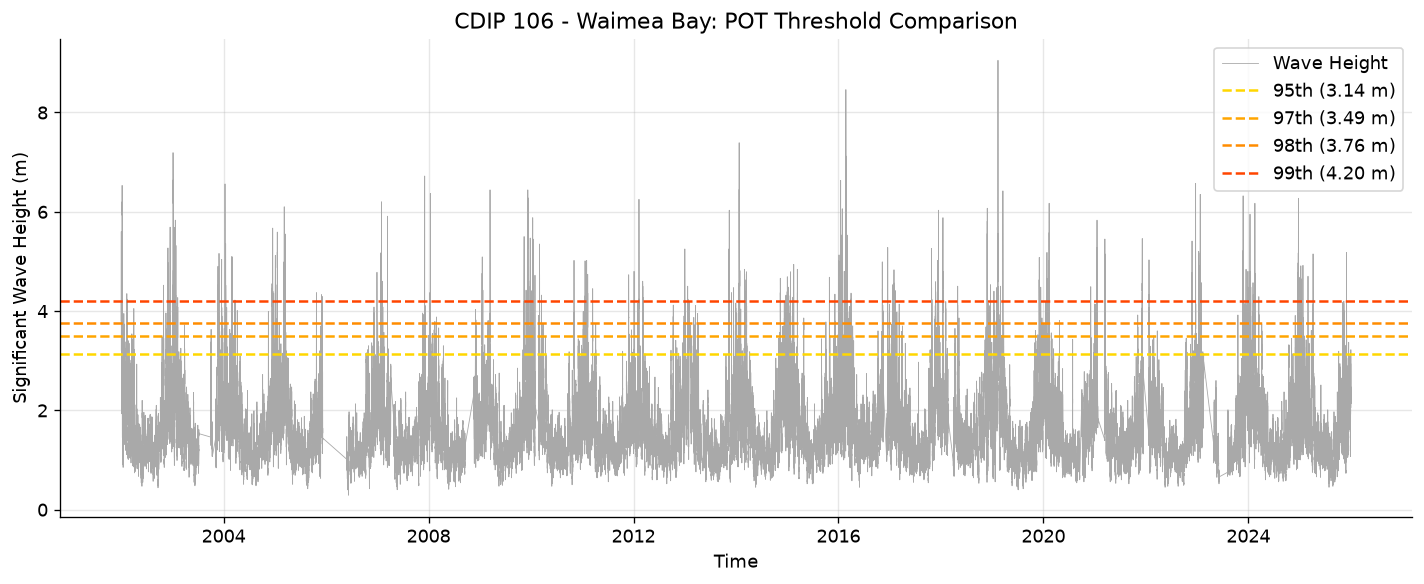

,Percentile,Threshold (m),Observations Above Threshold
0,95th,3.14,19008
1,97th,3.49,11468
2,98th,3.76,7643
3,99th,4.20,3780


In [9]:
# Compare potential POT thresholds
percentiles = [0.95, 0.97, 0.98, 0.99]
colors = ['gold', 'orange', 'darkorange', 'orangered']

# Plot wave height time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df['Time'], df['Hs'],
        color=WAVE_COLOR, linewidth=0.5, label='Wave Height')

# Calculate and plot thresholds
thresh_results = []

for p, color in zip(percentiles, colors):
    u = df['Hs'].quantile(p)
    n = (df['Hs'] > u).sum()

    ax.axhline(u, color=color, linestyle='--',
               linewidth=1.5, label=f'{p*100:.0f}th ({u:.2f} m)')

    thresh_results.append([f'{p*100:.0f}th', round(u, 2), n])

# Format plot
ax.set_xlabel('Time')
ax.set_ylabel('Significant Wave Height (m)')
ax.set_title('CDIP 106 - Waimea Bay: POT Threshold Comparison')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Display threshold comparison table
threshold_table = pd.DataFrame(
    thresh_results,
    columns=['Percentile', 'Threshold (m)', 'Observations Above Threshold']
)

display(threshold_table)

Based on the number of observations retained and our interest in larger wave events, we select the 99th-percentile threshold (4.20 m) for this demonstration. 

**Important:** This is an illustrative choice; threshold suitability has not been formally evaluated.

### Declustering Extreme Events

Consecutive wave-height observations above the threshold may belong to the same storm.

To avoid treating multiple measurements from a single event as independent extremes, we group nearby exceedances into clusters and retain only the maximum wave height from each cluster.

For this example, we use a **48-hour separation period** between exceedance clusters.

This reduces the original 3,780 exceedance observations to 148 selected storm peaks.

**Important:** The 48-hour separation is an assumed declustering interval. It does not guarantee statistical independence and should be evaluated for more rigorous applications.

In [10]:
# POT settings
threshold = df['Hs'].quantile(0.99)
separation = pd.Timedelta(hours=48)

# Select observations above the threshold
exceedances = df[df['Hs'] > threshold].copy()
exceedances = exceedances.sort_values('Time')

# Start a new cluster after 48 hours without an exceedance
exceedances['Cluster'] = (
    exceedances['Time'].diff().gt(separation).cumsum()
)

# Keep the maximum wave height from each cluster
pot_peaks = exceedances.loc[
    exceedances.groupby('Cluster')['Hs'].idxmax()
].copy()

# Display results
print(f"Threshold: {threshold:.2f} m")
print(f"Observations above threshold: {len(exceedances)}")
print(f"Declustered storm peaks: {len(pot_peaks)}")

pot_peaks[['Time', 'Hs']].head()

Threshold: 4.20 m
Observations above threshold: 3780
Declustered storm peaks: 148


,Time,Hs
794,2002-01-01 13:36:12+00:00,5.60
925,2002-01-04 07:06:11+00:00,4.21
1075,2002-01-07 10:06:13+00:00,6.53
2678,2002-02-09 19:36:15+00:00,4.35
14806,2002-10-29 09:06:29+00:00,4.52


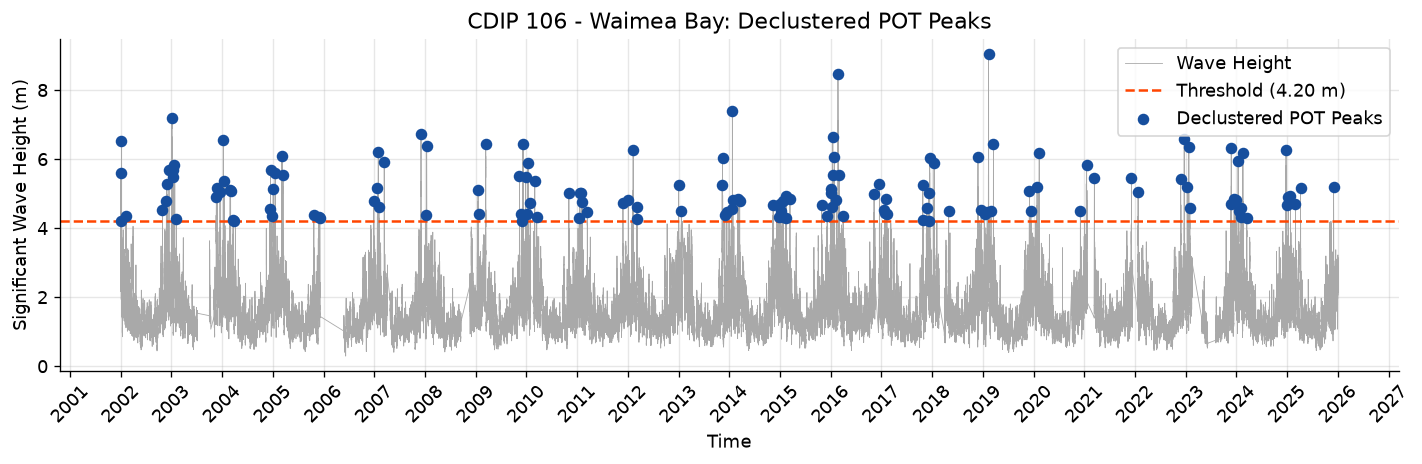

In [11]:
# Plot full time series
plt.figure(figsize=(12, 4))
plt.plot(df['Time'], df['Hs'],
         color=WAVE_COLOR, linewidth=0.5, label='Wave Height')

# Plot threshold
plt.axhline(y=threshold, color='orangered', linestyle='--',
            linewidth=1.5, label=f'Threshold ({threshold:.2f} m)')

# Mark declustered POT peaks
plt.scatter(pot_peaks['Time'], pot_peaks['Hs'],
            color=POT_COLOR, s=35, label='Declustered POT Peaks', zorder=3)

# Format axes
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.xticks(rotation=45)
plt.xlabel('Time')
plt.ylabel('Significant Wave Height (m)')
plt.title('CDIP 106 - Waimea Bay: Declustered POT Peaks')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Fitting the GPD Distribution

The Generalized Pareto Distribution models the amount by which selected storm peaks exceed the threshold.


$$
Y = H_s-u
$$

where $u$ is the selected threshold.


We fit the GPD to the **excess wave heights**, not the original peak heights.

The fitted distribution is characterized by the threshold, scale parameter, and shape parameter.

Unlike the GEV implementation, SciPy's GPD shape parameter uses the same sign convention as our lecture.

In [12]:
# Calculate exceedances above the threshold
excess = pot_peaks['Hs'].values - threshold

# Fit GPD distribution
shape_gpd, loc_gpd, scale_gpd = genpareto.fit(excess, floc=0)

# Convert to lecture parameter notation
A_gpd = threshold
B_gpd = scale_gpd
C_gpd = shape_gpd

# Display fitted parameters
print(f"Location / Threshold (A): {A_gpd:.3f} m")
print(f"Scale (B): {B_gpd:.3f} m")
print(f"Shape (C): {C_gpd:.3f}")
print(f"Number of storm peaks: {len(excess)}")

Location / Threshold (A): 4.200 m
Scale (B): 1.048 m
Shape (C): -0.115
Number of storm peaks: 148


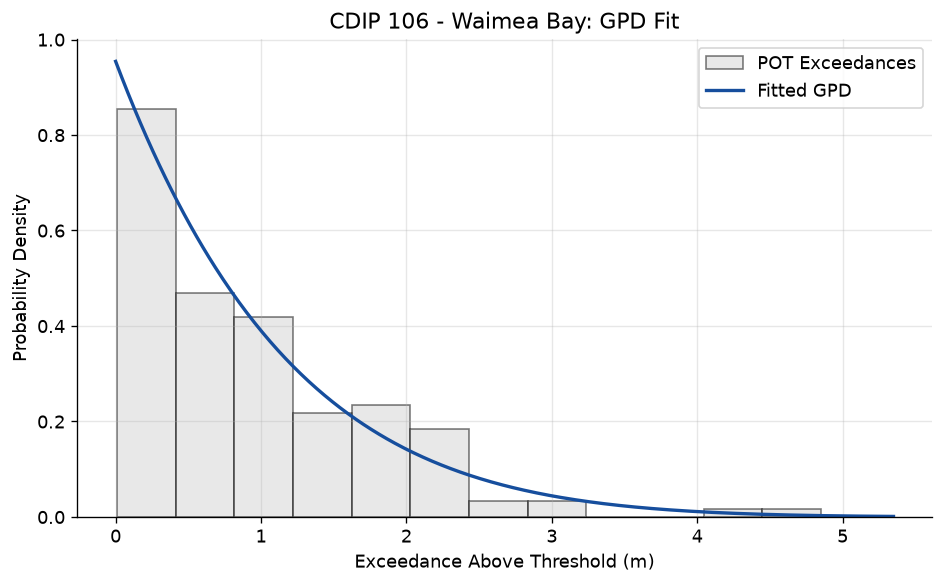

In [13]:
# Generate exceedance values for fitted GPD curve
x = np.linspace(0, excess.max() + 0.5, 500)

# Calculate fitted GPD probability density
pdf_gpd = genpareto.pdf(x, shape_gpd, loc=0, scale=B_gpd)

# Plot observed exceedances and fitted GPD
plt.figure(figsize=(8, 5))

plt.hist(excess, bins=12, density=True, alpha=0.5,
         color='lightgray', edgecolor='black', label='POT Exceedances')

plt.plot(x, pdf_gpd, color=POT_COLOR, linewidth=2,
         label='Fitted GPD')

plt.xlabel('Exceedance Above Threshold (m)')
plt.ylabel('Probability Density')
plt.title('CDIP 106 - Waimea Bay: GPD Fit')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Estimating POT/GPD Return Levels

POT retains multiple extreme events per year, so return-level calculations must account for both:

- The magnitude distribution of threshold exceedances
- The average annual frequency of declustered threshold-exceedance events

The annual event rate is estimated as:


$$
\lambda = \frac{N_{\mathrm{events}}}{N_{\mathrm{years}}}
$$


For this demonstration, we identify 148 events over 24 calendar years, giving approximately 6.17 selected events per year.

We combine this rate with the fitted GPD to estimate return levels for 10-, 25-, 50-, and 100-year return periods.

In [14]:
# Number of calendar years represented in the analysis
n_years = df['Time'].dt.year.nunique()

# Average number of declustered storm peaks per calendar year
event_rate = len(pot_peaks) / n_years

# Return periods (years)
T = np.array([10, 25, 50, 100])

# Calculate GPD return levels
return_levels_gpd = threshold + (B_gpd / C_gpd) * (
    (event_rate * T)**C_gpd - 1
)

# Display results
gpd_results = pd.DataFrame({
    'Return Period (years)': T,
    'Return Level (m)': return_levels_gpd
})

print(f"Average storm events per year: {event_rate:.2f}")
print(gpd_results.round(2))

Average storm events per year: 6.17
   Return Period (years)  Return Level (m)
0                     10              7.64
1                     25              8.21
2                     50              8.60
3                    100              8.96


These return levels are illustrative estimates. Missing observations, threshold selection, event dependence, and model uncertainty have not been fully evaluated. The estimates should not be interpreted as validated design values.

## 5. Comparing AMM/GEV and POT/GPD

Both methods estimate extreme-event magnitudes but use different approaches to selecting observations.

- **AMM/GEV:** 24 annual maxima
- **POT/GPD:** 148 declustered storm peaks

We compare return levels from the two fitted models to evaluate how event selection and distribution fitting influence the results.

**Discussion:**
- Which method predicts larger return levels?
- How do the differences change with increasing return period?
- Does agreement between the methods guarantee accurate predictions?

In [15]:
# Compare return levels from both methods
comparison = pd.DataFrame({
    'Return Period (years)': T,
    'AMM / GEV (m)': return_levels,
    'POT / GPD (m)': return_levels_gpd
})

display(comparison.round(2))

,Return Period (years),AMM / GEV (m),POT / GPD (m)
0,10,7.62,7.64
1,25,8.26,8.21
2,50,8.71,8.60
3,100,9.14,8.96


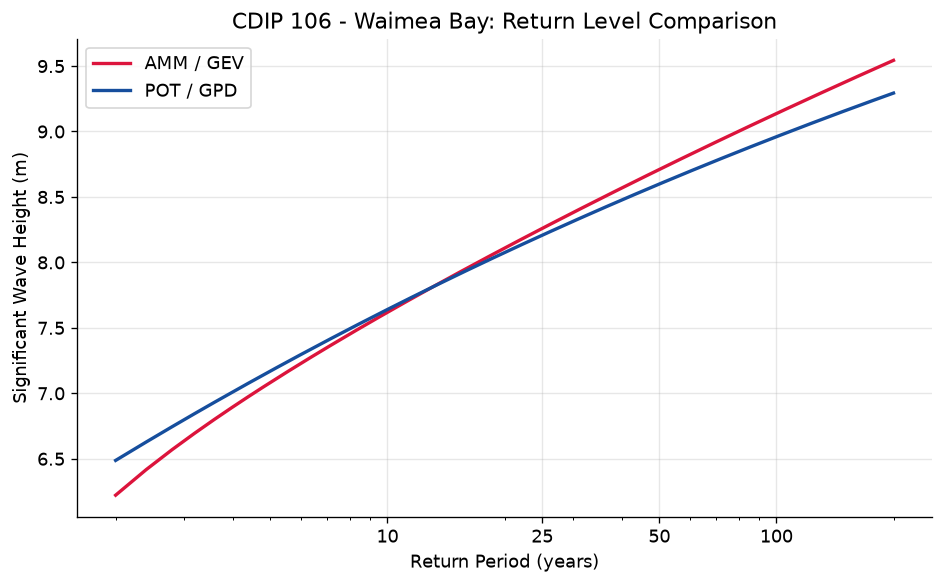

In [16]:
# Return periods from 2 to 200 years
T_plot = np.linspace(2, 200, 500)

# GEV return levels
gev_levels = genextreme.ppf(1 - 1/T_plot, shape, loc=A, scale=B)

# GPD return levels
gpd_levels = threshold + (B_gpd / C_gpd) * (
    (event_rate * T_plot)**C_gpd - 1
)

# Plot comparison
plt.figure(figsize=(8, 5))

plt.plot(T_plot, gev_levels, color=AMM_COLOR,
         linewidth=2, label='AMM / GEV')

plt.plot(T_plot, gpd_levels, color=POT_COLOR,
         linewidth=2, label='POT / GPD')

plt.xscale('log')
plt.xticks([10, 25, 50, 100], ['10', '25', '50', '100'])
plt.xlabel('Return Period (years)')
plt.ylabel('Significant Wave Height (m)')
plt.title('CDIP 106 - Waimea Bay: Return Level Comparison')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Evaluating Model Fit

Fitting a probability distribution does not guarantee that it adequately represents the observed extreme events.

A quantile–quantile (Q–Q) plot compares quantiles predicted by a fitted distribution against quantiles of the observed data.

**Interpreting Q–Q plots:**
- Points near the diagonal indicate agreement between observed and modeled quantiles.
- Systematic deviations may indicate that the fitted distribution does not adequately represent the observations.
- Deviations at the largest quantiles are especially important for extreme value analysis.

We compare Q–Q plots for the GEV and GPD fits to assess how well each model represents the selected extreme observations.

**Discussion:** Which parts of the fitted distributions show the greatest disagreement with observations?

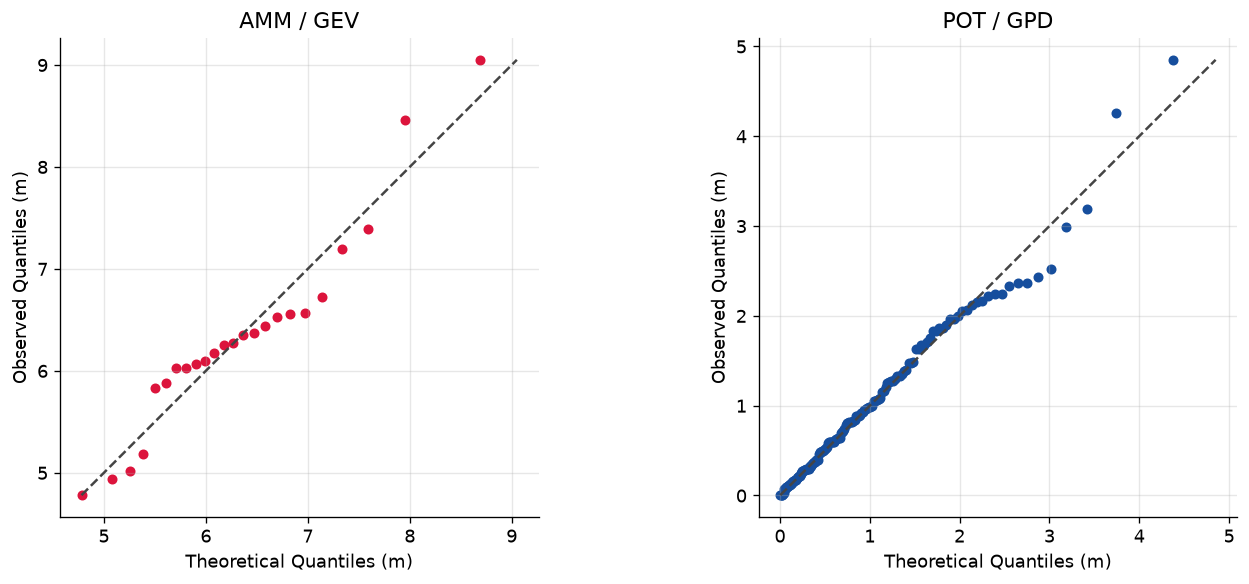

In [17]:
# Create Q-Q plots for GEV and GPD
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# GEV: annual maxima
observed_gev = np.sort(Hs_max)
p_gev = (np.arange(1, len(observed_gev) + 1) - 0.5) / len(observed_gev)
predicted_gev = genextreme.ppf(p_gev, shape, loc=A, scale=B)

# GPD: threshold exceedances
observed_gpd = np.sort(excess)
p_gpd = (np.arange(1, len(observed_gpd) + 1) - 0.5) / len(observed_gpd)
predicted_gpd = genpareto.ppf(p_gpd, shape_gpd, loc=0, scale=B_gpd)

# Plot both distributions
for ax, observed, predicted, title, color in zip(
    axes,
    [observed_gev, observed_gpd],
    [predicted_gev, predicted_gpd],
    ['AMM / GEV', 'POT / GPD'],
    [AMM_COLOR, POT_COLOR]
):
    ax.scatter(predicted, observed, color=color, s=25)

    limits = [min(predicted.min(), observed.min()),
              max(predicted.max(), observed.max())]

    ax.plot(limits, limits, color=REF_COLOR, linestyle='--')

    ax.set_xlabel('Theoretical Quantiles (m)')
    ax.set_ylabel('Observed Quantiles (m)')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()